# SHL Grammar Scoring Engine for Spoken English

**Task.** Predict a continuous MOS grammar score (0–5) for 45–60 s speech clips (769 train / 216 test).
**Metric.** Pearson correlation and RMSE.

## Results at a glance

| | Pearson | RMSE |
|---|---|---|
| **5-fold cross-validation, out-of-fold** (test-length-weighted, nested stacker, see §4, §8) | 0.854 | **0.499** (0.501 averaged over 5 stacker splits) |
| **Training data RMSE** (final ensemble, all 732 training clips, see §10) | 0.872 | **0.496** |
| Kaggle public leaderboard (lower is better) | | **0.3417** |

The training RMSE is close to the CV RMSE because the stacker's inputs are the base models' *out-of-fold* predictions;
the in-sample training RMSE of the individual refittable models (0.16–0.39) is also printed in §10.

## Pipeline

```
audio (16 kHz)
 ├─► Whisper turbo ASR (verbatim prompt, word timestamps) ─► transcript
 │      ├─► DeBERTa-v3-base / -large, fine-tuned (regression) ──────────────┐
 │      └─► grammar & fluency features + mpnet embedding ─► Ridge/SVR/LGBM ──┤
 ├─► WavLM-large (frozen, best layers)                                      │
 │      ├─► clip mean (+ std) ─► Ridge / SVR ────────────────────────────────┤
 │      └─► 80 ms frame sequence ─► attention-pooling head ───────────────────┤─► non-negative linear stacker
 └─► Whisper-large-v3 encoder (frozen, best layers)                         │     ─► per-length bias correction
        ├─► clip mean (+ std) ─► Ridge / SVR ────────────────────────────────┤     ─► score
        └─► 80 ms frame sequence ─► attention-pooling head ───────────────────┘
```

## Key decisions (each one is justified with data below)
1. **Removed 37 artificial score-0 clips** (§3): a separate batch (ids 5037–5073, ~10 dB louder, no silence) that does not exist in the test set.
2. **Corrected a train/test length shift** (§4): 69 % of test clips are short (<50 s) vs 24 % in train, and short clips score 0.46 lower → importance weights + per-length bias correction.
3. **Text + audio**: a frozen speech model alone is almost as good as a fine-tuned text model; combining them gave the biggest late gain (§7–§9).
4. **Honest evaluation**: every model uses the same 5 folds; the stacker is evaluated with a *second*, different fold split (nested), so its weights never see the rows they are scored on.
5. **Keep the time dimension of the speech** (§7c): small attention heads over 80 ms frames of the frozen speech models, instead of one averaged vector per clip, gave the last real leaderboard gain (0.3510 → 0.3417).
6. **Checked why the score plateaued** (§9b, §9c): the test set contains prompts that never occur in training, and some Whisper transcripts are broken — both were measured and found to explain only a small part of the remaining error.

> **How to run.** `RUN_FULL = False` (default) loads the expensive artefacts (transcripts, DeBERTa and attention-head out-of-fold predictions, frozen speech-model features) from the attached datasets `shl-work-v3` and `shl-work-v18-add` and recomputes everything else (~15 min, CPU is enough).
> `RUN_FULL = True` recomputes every stage from raw audio (~4 h on a T4 GPU). The code for every stage is in this notebook.

## 0. Setup

In [33]:
# !pip install -q openai-whisper        # only needed when RUN_FULL = True
import os, re, glob, json, gc, difflib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, soundfile as sf, librosa, torch
from scipy.stats import pearsonr, spearmanr
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
warnings.filterwarnings('ignore')

DATA_DIR = '/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
WORK_DIR = '/kaggle/working'
SEED = 42
RUN_FULL = False      # False: load cached artefacts (~15 min). True: recompute everything from audio (~3 h on 2x T4)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
np.random.seed(SEED); torch.manual_seed(SEED)

CACHE_DATASETS = ['anmolkamboz/shl-work-v3', 'anmolkamboz/shl-work-v18-add']     # cached artefacts used when RUN_FULL = False
CACHE_ROOTS = ['/kaggle/input']
def find(name):
    # cached artefact anywhere in the attached shl-work datasets, or None
    for base in CACHE_ROOTS:
        for root, dirs, files in os.walk(base, followlinks=True):
            if 'competitions' in root: dirs[:] = []; continue
            if name in files: return os.path.join(root, name)
    return None
if not RUN_FULL and (find('topic_labels.npy') is None or find('oof_head_wh.npy') is None):
    # datasets attached after the session started are sometimes not mounted yet -> fetch them directly
    import kagglehub
    for d in CACHE_DATASETS:
        try: CACHE_ROOTS.append(kagglehub.dataset_download(d)); print('loaded', d)
        except Exception as e: print(f'could not load {d}: {type(e).__name__} (artefacts from it will be recomputed)')
if not RUN_FULL:
    missing = [n for n in ['transcripts.csv', 'handcrafted_features.csv', 'oof_base.npy', 'wavlm_large_layers.npy',
                           'whisper_enc_layers.npy', 'topic_labels.npy'] if find(n) is None]
    assert not missing, f'cached files not found: {missing} - attach the shl-work-v3 dataset (or set RUN_FULL = True)'
    print('cached artefacts found | frame-level heads cached:', find('oof_head_wh.npy') is not None)

def need(name):
    p = find(name)
    assert p is not None, f'{name} not found - attach the shl-work-v3 and shl-work-v18-add datasets or set RUN_FULL = True'
    return p

print('device:', DEVICE, '| RUN_FULL:', RUN_FULL)

cached artefacts found | frame-level heads cached: True
device: cuda | RUN_FULL: False


## 1. Data loading

In [34]:
train_df = pd.read_csv(f'{DATA_DIR}/train.csv')
test_df  = pd.read_csv(f'{DATA_DIR}/test.csv')
def file_col(d): return [c for c in d.columns if d[c].dtype == object][0]
FILE_COL, TEST_FILE_COL = file_col(train_df), file_col(test_df)
LABEL_COL = [c for c in train_df.columns if c != FILE_COL and pd.api.types.is_numeric_dtype(train_df[c])][0]
SUB_ID_COL, SUB_TARGET_COL = 'filename', 'label'
# NOTE: sample_submission.csv has 204 rows whose ids mostly do not appear in test.csv (216 rows),
# so the submission is written in test.csv order with the sample's column names.

def audio_path(n, split):
    n = str(n); n = n if n.endswith('.wav') else n + '.wav'
    return os.path.join(DATA_DIR, split, n)
train_df['path'] = train_df[FILE_COL].map(lambda n: audio_path(n, 'train'))
test_df['path']  = test_df[TEST_FILE_COL].map(lambda n: audio_path(n, 'test'))
all_df = pd.concat([train_df[['path']].assign(split='train'), test_df[['path']].assign(split='test')], ignore_index=True)
all_df['duration'] = all_df.path.map(lambda p: sf.info(p).duration)
is_tr = (all_df.split == 'train').values
y = train_df[LABEL_COL].values.astype(float)
print(f'train {len(train_df)} | test {len(test_df)} | missing audio:', (~all_df.path.map(os.path.exists)).sum())
print('label counts:', pd.Series(y).value_counts().sort_index().to_dict())

train 769 | test 216 | missing audio: 0
label counts: {0.0: 37, 1.0: 1, 1.5: 3, 2.0: 102, 2.5: 79, 3.0: 174, 3.5: 64, 4.0: 124, 4.5: 52, 5.0: 133}


### 1b. Speech-to-text (Whisper turbo)
Whisper is trained on clean captions and tends to *silently fix* grammar and drop fillers — exactly the evidence we need.
A disfluent `initial_prompt` biases it towards a verbatim transcript. Word timestamps are kept for fluency features.

In [35]:
PROMPT = "Umm, so, I- I was like, uh, thinking that, hmm... Okay, so he go to the, um, the market and they was, like, happy."

def run_whisper_asr(paths):
    import whisper
    asr = whisper.load_model('turbo', device=DEVICE)
    rows = []
    for i, p in enumerate(paths):
        audio, _ = librosa.load(p, sr=16000, mono=True)
        r = asr.transcribe(audio.astype(np.float32), language='en', initial_prompt=PROMPT,
                           word_timestamps=True, fp16=(DEVICE == 'cuda'))
        words = [(w['word'], float(w['start']), float(w['end'])) for s in r['segments'] for w in s.get('words', [])]
        rows.append({'path': p, 'text': r['text'].strip(), 'words': json.dumps(words)})
        if i % 100 == 0: print(f'{i}/{len(paths)}', r['text'][:100])
    del asr; gc.collect(); torch.cuda.empty_cache()
    return pd.DataFrame(rows)

if RUN_FULL or find('transcripts.csv') is None:
    tr = run_whisper_asr(list(all_df.path)); tr.to_csv(f'{WORK_DIR}/transcripts.csv', index=False)
else:
    tr = pd.read_csv(need('transcripts.csv'))
tr['key'] = tr.path.map(os.path.basename) + '|' + tr.path.map(lambda p: os.path.basename(os.path.dirname(p)))
all_df['key'] = all_df.path.map(os.path.basename) + '|' + all_df.split
all_df = all_df.merge(tr[['key', 'text', 'words']], on='key', how='left')
all_df['text'] = all_df.text.fillna('').astype(str); all_df['words'] = all_df.words.fillna('[]')
print('transcripts:', (all_df.text.str.len() > 0).sum(), '/', len(all_df))
for s in [2.0, 3.0, 5.0]:
    i = np.where(y == s)[0][0]
    print(f'\n[score {s}]', all_df.text[i][:220])

transcripts: 985 / 985

[score 2.0] Once upon a time, we, with five friends, went on a tour, went on a tour with a driver agent on a Manali. And we stayed at a resort. And we stayed around, we stayed at a resort, and after that, we stayed, when we checked 

[score 3.0] Well, this, the playground is very, very beautiful and fun. There are, there are playtons, like, the merry-go-round, the swing. The students usually enjoy the swing. It has to be, like, um, it's more like a game of care.

[score 5.0] The journey to Switzerland is an adventure in itself, whether you arrive by plane, train, or car. If you fly into Zurich or Genova, you will be greeted by stunning views of Swiss Alps as you plane descent towards the air


## 2. Exploratory analysis

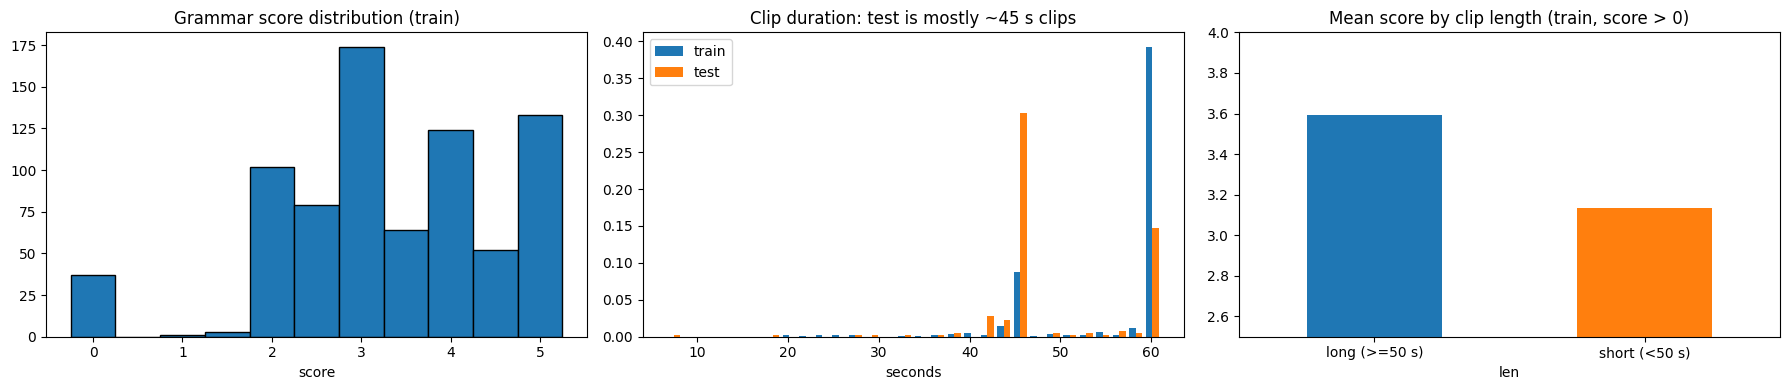

In [36]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].hist(y, bins=np.arange(-0.25, 5.5, 0.5), edgecolor='k'); ax[0].set_title('Grammar score distribution (train)'); ax[0].set_xlabel('score')
ax[1].hist([all_df.duration[is_tr], all_df.duration[~is_tr]], bins=30, label=['train', 'test'], density=True)
ax[1].set_title('Clip duration: test is mostly ~45 s clips'); ax[1].set_xlabel('seconds'); ax[1].legend()
d_all = all_df.duration.values
grp = pd.DataFrame({'len': np.where(d_all[is_tr] < 50, 'short (<50 s)', 'long (>=50 s)'), 'score': y})[y > 0]
grp.groupby('len').score.mean().plot.bar(ax=ax[2], color=['tab:blue', 'tab:orange'], rot=0)
ax[2].set_title('Mean score by clip length (train, score > 0)'); ax[2].set_ylim(2.5, 4)
plt.tight_layout(); plt.show()

## 3. Data quality: an artificial score-0 batch
Score 0 is not part of the 1–5 rubric. All 37 score-0 clips share file ids 5037–5073, are ~10 dB louder and contain **no silent frames at all**,
while their transcripts read like normal 3–4 level speech. No test clip has this signature (test ids are 0–220).
They are a separate artificial batch, so they are **removed from training**.

                  file_id  duration  rms_db  silence_frac
group                                                    
test                107.5     45.06  -29.37          0.32
train, score 0     5055.0     60.07  -18.09          0.00
train, score > 0    380.5     60.07  -27.54          0.34


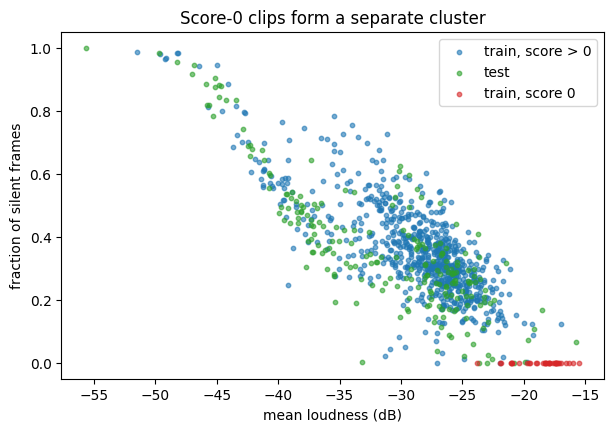

training clips kept: 732


In [37]:
def loudness_stats(p):
    a, _ = librosa.load(p, sr=16000, mono=True)
    rms = librosa.feature.rms(y=a)[0]
    return 20 * np.log10(rms.mean() + 1e-9), (rms < 0.01).mean()

ls = np.array([loudness_stats(p) for p in all_df.path])
all_df['rms_db'], all_df['silence_frac'] = ls[:, 0], ls[:, 1]
all_df['file_id'] = all_df.path.str.extract(r'audio_(\d+)')[0].astype(int)
all_df['label'] = np.nan; all_df.loc[is_tr, 'label'] = y
all_df['group'] = np.where(~is_tr, 'test', np.where(all_df.label == 0, 'train, score 0', 'train, score > 0'))
print(all_df.groupby('group')[['file_id', 'duration', 'rms_db', 'silence_frac']].median().round(2).to_string())

plt.figure(figsize=(7, 4.5))
for g, c in [('train, score > 0', 'tab:blue'), ('test', 'tab:green'), ('train, score 0', 'tab:red')]:
    m = all_df.group == g; plt.scatter(all_df.rms_db[m], all_df.silence_frac[m], s=10, alpha=0.6, c=c, label=g)
plt.xlabel('mean loudness (dB)'); plt.ylabel('fraction of silent frames'); plt.legend(); plt.title('Score-0 clips form a separate cluster')
plt.show()

nz = y > 0                 # keep the 732 rubric-scored clips
y2 = y[nz]
print('training clips kept:', nz.sum())

## 4. Train/test shift: clip length → weights, bias correction, folds
* 69 % of test clips are short (<50 s) vs 24 % of train clips, and short clips score ~0.46 lower.
* **Importance weights** make the training mix look like the test mix (short ×2.84, long ×0.41). They are used in every model's loss
  and in every evaluation ("test-weighted" metrics).
* **Per-length bias correction**: after modelling, the mean out-of-fold error of short and of long clips is subtracted (2 numbers).
* **One fixed 5-fold split**, stratified by score *and* length, shared by every model, so out-of-fold (OOF) predictions are stackable.

In [38]:
d_tr, d_te = d_all[is_tr], d_all[~is_tr]
short_tr, short_te = d_tr[nz] < 50, d_te < 50
p_te, p_tr = short_te.mean(), short_tr.mean()
w5 = np.where(short_tr, p_te / p_tr, (1 - p_te) / (1 - p_tr))
print(f'short clips: train {p_tr:.0%}, test {p_te:.0%} -> weights short {p_te / p_tr:.2f}, long {(1 - p_te) / (1 - p_tr):.2f}')
strata5 = np.clip(np.round(y2).astype(int), 2, 5) * 2 + short_tr
skf  = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)        # base models
skf2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)    # stacker (nested evaluation)

def rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))
def wrmse(a, b, w): return float(np.sqrt(np.average((a - b) ** 2, weights=w)))
def wmae(a, b, w): return float(np.average(np.abs(a - b), weights=w))
def wpearson(a, b, w):
    ma, mb = np.average(a, weights=w), np.average(b, weights=w)
    return float(np.average((a - ma) * (b - mb), weights=w) /
                 np.sqrt(np.average((a - ma) ** 2, weights=w) * np.average((b - mb) ** 2, weights=w)))
def wreport(name, yt, yp, w=None):
    w = w5 if w is None else w
    print(f'{name:>26s} | test-weighted Pearson {wpearson(yt, yp, w):.4f} | RMSE {wrmse(yt, yp, w):.4f}')
def fit_w(model, X, yy, w):
    if hasattr(model, 'steps'): return model.fit(X, yy, **{f'{model.steps[-1][0]}__sample_weight': w})
    return model.fit(X, yy, sample_weight=w)
def bias_correct(oof_p, test_p):
    b = {s: (oof_p[short_tr == s] - y2[short_tr == s]).mean() for s in (True, False)}
    return (np.clip(oof_p - np.where(short_tr, b[True], b[False]), 1, 5),
            np.clip(test_p - np.where(short_te, b[True], b[False]), 1, 5))
def cv_model(make, Xtr, Xte):
    oof, te = np.zeros(len(y2)), np.zeros(len(Xte))
    for tr_idx, va_idx in skf.split(Xtr, strata5):
        m = fit_w(make(), Xtr[tr_idx], y2[tr_idx], w5[tr_idx])
        oof[va_idx] = m.predict(Xtr[va_idx]); te += m.predict(Xte) / skf.n_splits
    return oof, te
make_ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(0, 5, 30)))
make_svr   = lambda: make_pipeline(StandardScaler(), SVR(C=3.0, epsilon=0.1, gamma='scale'))

short clips: train 24%, test 69% -> weights short 2.84, long 0.41


## 5. Text features
### 5a. Hand-crafted grammar & fluency features
* **Grammar:** GEC word-edit rate (a T5 grammar corrector rewrites each sentence; edits per word ≈ number of mistakes),
  CoLA acceptability (RoBERTa: P(sentence is grammatical)), GPT-2 log-perplexity.
* **Fluency / complexity** (from word timestamps): words/sec, long pauses/min, mean & max pause, filler rate, repetitions,
  words per sentence, type-token ratio, word length.

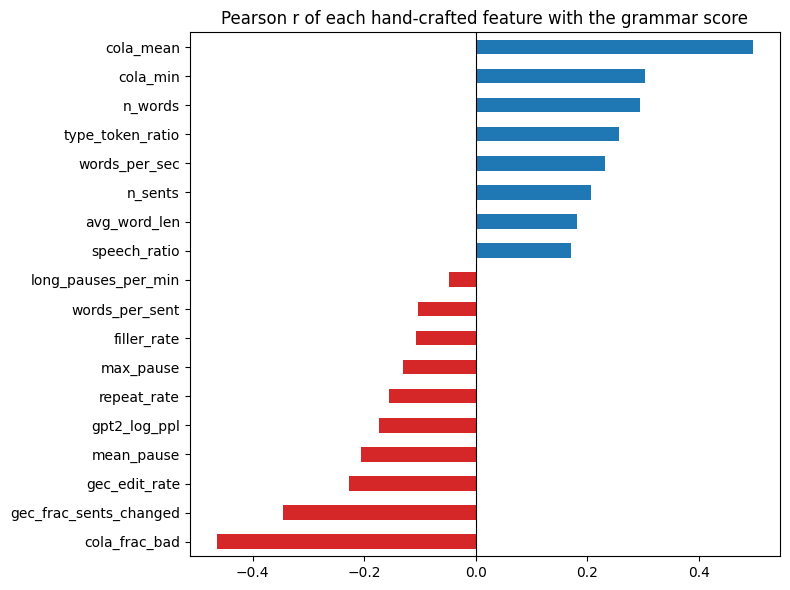

In [39]:
FILLERS = {'um', 'umm', 'uh', 'uhm', 'er', 'erm', 'hmm', 'ah', 'mm'}
def split_sents(text):
    s = [x.strip() for x in re.split(r'(?<=[.!?])\s+', text) if len(x.strip().split()) >= 2]
    return s if s else [text if text else 'empty']

def basic_feats(text, words_json, dur):
    words = json.loads(words_json); toks = re.findall(r"[a-z']+", text.lower()); n = max(len(toks), 1); sents = split_sents(text)
    gaps = np.clip([b[1] - a[2] for a, b in zip(words[:-1], words[1:])], 0, None) if len(words) > 1 else np.zeros(1)
    return {'n_words': len(toks), 'n_sents': len(sents), 'words_per_sent': len(toks) / len(sents),
            'type_token_ratio': len(set(toks)) / n, 'avg_word_len': np.mean([len(t) for t in toks]) if toks else 0.0,
            'filler_rate': sum(t in FILLERS for t in toks) / n, 'repeat_rate': sum(a == b for a, b in zip(toks, toks[1:])) / n,
            'words_per_sec': len(toks) / max(dur, 1e-6), 'long_pauses_per_min': (gaps > 0.5).sum() / max(dur, 1e-6) * 60,
            'mean_pause': float(np.mean(gaps)), 'max_pause': float(np.max(gaps)),
            'speech_ratio': sum(e - s for _, s, e in words) / max(dur, 1e-6)}

def compute_handcrafted():
    from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification, AutoModelForSeq2SeqLM
    basic = pd.DataFrame([basic_feats(t, w, d) for t, w, d in zip(all_df.text, all_df.words, all_df.duration)])
    flat = [(i, s) for i, t in enumerate(all_df.text) for s in split_sents(t)]
    fdoc, fs = np.array([i for i, _ in flat]), [s for _, s in flat]
    # GEC edit rate
    gt = AutoTokenizer.from_pretrained('vennify/t5-base-grammar-correction')
    gm = AutoModelForSeq2SeqLM.from_pretrained('vennify/t5-base-grammar-correction').float().to(DEVICE).eval()
    corr = []
    with torch.no_grad():
        for i in range(0, len(fs), 64):
            enc = gt(['grammar: ' + s for s in fs[i:i + 64]], return_tensors='pt', padding=True, truncation=True, max_length=128).to(DEVICE)
            corr += gt.batch_decode(gm.generate(**enc, max_new_tokens=128, num_beams=1), skip_special_tokens=True)
    def edits(a, b):
        a, b = re.findall(r"[a-z']+", a.lower()), re.findall(r"[a-z']+", b.lower())
        ops = difflib.SequenceMatcher(None, a, b).get_opcodes()
        return sum(max(i2 - i1, j2 - j1) for t, i1, i2, j1, j2 in ops if t != 'equal'), max(len(a), 1)
    ed = np.array([edits(s, c) for s, c in zip(fs, corr)])
    g = pd.DataFrame({'doc': fdoc, 'e': ed[:, 0], 'n': ed[:, 1], 'ch': ed[:, 0] > 0}).groupby('doc')
    gec = pd.DataFrame({'gec_edit_rate': g.e.sum() / g.n.sum(), 'gec_frac_sents_changed': g.ch.mean()}).reindex(range(len(all_df))).fillna(0)
    # CoLA acceptability
    ct = AutoTokenizer.from_pretrained('textattack/roberta-base-CoLA')
    cm = AutoModelForSequenceClassification.from_pretrained('textattack/roberta-base-CoLA').float().to(DEVICE).eval()
    pr = []
    with torch.no_grad():
        for i in range(0, len(fs), 128):
            enc = ct(fs[i:i + 128], return_tensors='pt', padding=True, truncation=True, max_length=128).to(DEVICE)
            pr.append(cm(**enc).logits.softmax(-1)[:, 1].float().cpu().numpy())
    g = pd.DataFrame({'doc': fdoc, 'p': np.concatenate(pr)}).groupby('doc').p
    cola = pd.DataFrame({'cola_mean': g.mean(), 'cola_min': g.min(), 'cola_frac_bad': g.apply(lambda s: (s < 0.5).mean())}).reindex(range(len(all_df))).fillna(0.5)
    # GPT-2 log-perplexity
    lt = AutoTokenizer.from_pretrained('gpt2'); lm = AutoModelForCausalLM.from_pretrained('gpt2').float().to(DEVICE).eval()
    def lp(t):
        ids = lt(t, return_tensors='pt', truncation=True, max_length=1024).input_ids.to(DEVICE)
        if ids.shape[1] < 2: return np.nan
        with torch.no_grad(): return lm(ids, labels=ids).loss.item()
    gpt = pd.DataFrame({'gpt2_log_ppl': [lp(t) for t in all_df.text]}); gpt = gpt.fillna(gpt.median())
    return pd.concat([basic, gec, cola, gpt], axis=1)

if RUN_FULL or find('handcrafted_features.csv') is None:
    HAND = compute_handcrafted(); HAND.to_csv(f'{WORK_DIR}/handcrafted_features.csv', index=False)
else:
    HAND = pd.read_csv(need('handcrafted_features.csv'))
assert len(HAND) == len(all_df)

corr = pd.Series({c: pearsonr(HAND.loc[is_tr, c].values[nz], y2)[0] for c in HAND.columns}).sort_values()
plt.figure(figsize=(8, 6)); corr.plot.barh(color=['tab:red' if v < 0 else 'tab:blue' for v in corr])
plt.axvline(0, c='k', lw=0.8); plt.title('Pearson r of each hand-crafted feature with the grammar score'); plt.tight_layout(); plt.show()

### 5b. Sentence embedding of the transcript (all-mpnet-base-v2, mean pooled)

In [40]:
from transformers import AutoTokenizer, AutoModel
etok = AutoTokenizer.from_pretrained('sentence-transformers/all-mpnet-base-v2')
emod = AutoModel.from_pretrained('sentence-transformers/all-mpnet-base-v2').float().to(DEVICE).eval()
embs, texts = [], [t if t else 'empty' for t in all_df.text]
with torch.no_grad():
    for i in range(0, len(texts), 32):
        enc = etok(texts[i:i + 32], return_tensors='pt', padding=True, truncation=True, max_length=384).to(DEVICE)
        h = emod(**enc).last_hidden_state; m = enc.attention_mask.unsqueeze(-1).float()
        embs.append(torch.nn.functional.normalize((h * m).sum(1) / m.sum(1), dim=-1).cpu().numpy())
EMB = np.vstack(embs); del emod; gc.collect()
print('embedding matrix', EMB.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

embedding matrix (985, 768)


### 5c. Feature models (Ridge / SVR / LightGBM)
Hand-crafted features + duration + short-clip flag (+ embedding for Ridge/SVR), weighted loss, same folds. Their average is one stacker input (`feats`).

In [41]:
HAND5 = HAND.copy(); HAND5['duration'] = d_all; HAND5['is_short'] = (d_all < 50).astype(float)
H_tr5, H_te5 = HAND5[is_tr].values[nz], HAND5[~is_tr].values
X_tr5, X_te5 = np.hstack([H_tr5, EMB[is_tr][nz]]), np.hstack([H_te5, EMB[~is_tr]])
make_ridge5 = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 4, 40)))
make_lgbm = lambda: lgb.LGBMRegressor(n_estimators=500, learning_rate=0.02, num_leaves=15, min_child_samples=15, subsample=0.8,
                                      subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1)
feat_models = {'ridge': (make_ridge5, X_tr5, X_te5), 'svr': (make_svr, X_tr5, X_te5), 'lgbm': (make_lgbm, H_tr5, H_te5)}
fo, ft = {}, {}
for n, (mk, Xa, Xb) in feat_models.items():
    fo[n], ft[n] = cv_model(mk, Xa, Xb); wreport(f'feature model: {n}', y2, fo[n])
oof_b5, test_b5 = np.mean(list(fo.values()), axis=0), np.mean(list(ft.values()), axis=0)
wreport('feature models (average)', y2, bias_correct(oof_b5, test_b5)[0])

      feature model: ridge | test-weighted Pearson 0.6737 | RMSE 0.7107
        feature model: svr | test-weighted Pearson 0.6789 | RMSE 0.7121
       feature model: lgbm | test-weighted Pearson 0.6588 | RMSE 0.7227
  feature models (average) | test-weighted Pearson 0.7284 | RMSE 0.6615


## 6. Fine-tuned DeBERTa-v3 on transcripts
Regression head on DeBERTa-v3 (base: 5 epochs, lr 2e-5, batch 16; large: 6 epochs, lr 1e-5, batch 4), standardised target,
**weighted MSE** with the test-mix weights, cosine schedule with warm-up, fp16 autocast with fp32 master weights,
no dropout (better for regression), last epoch only (no early stopping on the validation fold → no leakage).
Cached out-of-fold / test predictions are loaded unless `RUN_FULL = True`.

In [42]:
from transformers import AutoModelForSequenceClassification, get_cosine_schedule_with_warmup
texts_tr, texts_te = all_df.loc[is_tr, 'text'].values[nz], all_df.loc[~is_tr, 'text'].values
Y_MEAN, Y_STD = y2.mean(), y2.std()

def train_deberta(model_name, epochs, lr, bs, seed=SEED, max_len=256, splits=None):
    tok = AutoTokenizer.from_pretrained(model_name)
    enc_fn = lambda T: tok([t if t else 'empty' for t in T], truncation=True, max_length=max_len, padding='max_length', return_tensors='pt')
    e_tr, e_te = enc_fn(texts_tr), enc_fn(texts_te)
    yt = torch.tensor((y2 - Y_MEAN) / Y_STD, dtype=torch.float32); wt = torch.tensor(w5 / w5.mean(), dtype=torch.float32)
    sub = lambda e, idx: {k: v[torch.as_tensor(idx)] for k, v in e.items()}
    def predict(model, e):
        model.eval(); out = []
        with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
            for i in range(0, len(e['input_ids']), 64):
                out.append(model(**{k: v[i:i + 64].to(DEVICE) for k, v in e.items()}).logits.squeeze(-1).float().cpu().numpy())
        return np.concatenate(out) * Y_STD + Y_MEAN
    oof, test = np.zeros(len(y2)), np.zeros(len(texts_te))
    for fold, (tr_idx, va_idx) in enumerate(splits if splits is not None else skf.split(texts_tr, strata5)):
        torch.manual_seed(seed + fold); np.random.seed(seed + fold)
        model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=1, hidden_dropout_prob=0.0).float().to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
        steps = epochs * int(np.ceil(len(tr_idx) / bs)); sch = get_cosine_schedule_with_warmup(opt, int(0.1 * steps), steps)
        scaler = torch.amp.GradScaler('cuda')
        for ep in range(epochs):
            model.train(); perm = np.random.permutation(tr_idx)
            for i in range(0, len(perm), bs):
                idx = perm[i:i + bs]
                with torch.autocast('cuda', dtype=torch.float16):
                    pred = model(**{k: v.to(DEVICE) for k, v in sub(e_tr, idx).items()}).logits.squeeze(-1)
                loss = (wt[idx].to(DEVICE) * (pred.float() - yt[idx].to(DEVICE)) ** 2).mean()
                opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); sch.step()
        p = predict(model, sub(e_tr, va_idx)); oof[va_idx] = p; test += predict(model, e_te) / skf.n_splits
        print(f'  {model_name} fold {fold} | val Pearson {pearsonr(y2[va_idx], p)[0]:.4f} | RMSE {rmse(y2[va_idx], p):.4f}')
        del model, opt; gc.collect(); torch.cuda.empty_cache()
    return oof, test

if RUN_FULL or find('oof_base.npy') is None:
    oof_deb, test_deb = train_deberta('microsoft/deberta-v3-base', epochs=5, lr=2e-5, bs=16)
    oof_large, test_large = train_deberta('microsoft/deberta-v3-large', epochs=6, lr=1e-5, bs=4)
    for n, a in [('oof_base', oof_deb), ('test_base', test_deb), ('oof_large', oof_large), ('test_large', test_large)]:
        np.save(f'{WORK_DIR}/{n}.npy', a)
else:
    oof_deb, test_deb = np.load(need('oof_base.npy')), np.load(need('test_base.npy'))
    oof_large, test_large = np.load(need('oof_large.npy')), np.load(need('test_large.npy'))
wreport('DeBERTa-v3-base', y2, oof_deb); wreport('DeBERTa-v3-large', y2, oof_large)

           DeBERTa-v3-base | test-weighted Pearson 0.8135 | RMSE 0.5622
          DeBERTa-v3-large | test-weighted Pearson 0.7997 | RMSE 0.5797


## 7. Frozen speech models: layer-wise probing
Each clip is passed through **WavLM-large** (20 s chunks) and the **Whisper-large-v3 encoder** (30 s windows, padding frames ignored);
every layer's hidden states are mean-pooled over time. A weighted Ridge per layer shows *where* the grammar-relevant information lives.

WavLM layers (985, 25, 1024) | Whisper encoder layers (985, 33, 1280)


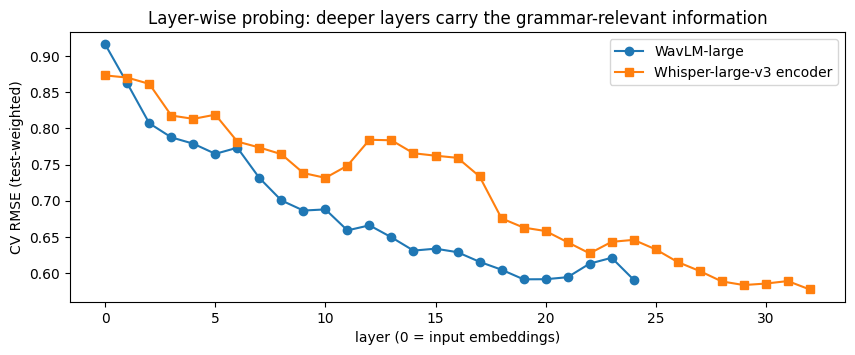

In [43]:
def extract_wavlm_layers(paths, chunk_s=20):
    from transformers import AutoFeatureExtractor, WavLMModel
    fe = AutoFeatureExtractor.from_pretrained('microsoft/wavlm-large')
    m = WavLMModel.from_pretrained('microsoft/wavlm-large').float().to(DEVICE).eval(); out = []
    with torch.inference_mode():
        for p in paths:
            a, _ = librosa.load(p, sr=16000, mono=True); sums, n = None, 0
            for s in range(0, len(a), chunk_s * 16000):
                piece = a[s:s + chunk_s * 16000]
                if len(piece) < 16000: continue
                x = fe(piece, sampling_rate=16000, return_tensors='pt').input_values.to(DEVICE)
                with torch.autocast('cuda', dtype=torch.float16, enabled=(DEVICE == 'cuda')):
                    hs = m(x, output_hidden_states=True).hidden_states
                l = torch.stack([h[0].float().sum(0) for h in hs]).cpu().numpy()
                sums = l if sums is None else sums + l; n += hs[0].shape[1]
            out.append(sums / max(n, 1))
    del m; gc.collect(); torch.cuda.empty_cache(); return np.stack(out)

def extract_whisper_encoder_layers(paths):
    from transformers import WhisperFeatureExtractor, WhisperModel
    fe = WhisperFeatureExtractor.from_pretrained('openai/whisper-large-v3')
    wm = WhisperModel.from_pretrained('openai/whisper-large-v3'); enc = wm.get_encoder().half().to(DEVICE).eval(); del wm
    out = []
    with torch.inference_mode():
        for p in paths:
            a, _ = librosa.load(p, sr=16000, mono=True); sums, n = None, 0
            for s in range(0, len(a), 30 * 16000):
                piece = a[s:s + 30 * 16000]
                if len(piece) < 16000: continue
                x = fe(piece, sampling_rate=16000, return_tensors='pt').input_features.half().to(DEVICE)
                hs = enc(x, output_hidden_states=True).hidden_states
                nv = min(1500, int(np.ceil(len(piece) / 16000 / 0.02)))        # encoder frames containing real audio
                l = torch.stack([h[0, :nv].float().sum(0) for h in hs]).cpu().numpy()
                sums = l if sums is None else sums + l; n += nv
            out.append(sums / max(n, 1))
    del enc; gc.collect(); torch.cuda.empty_cache(); return np.stack(out)

if RUN_FULL or find('wavlm_large_layers.npy') is None:
    AUD = extract_wavlm_layers(list(all_df.path)); np.save(f'{WORK_DIR}/wavlm_large_layers.npy', AUD.astype(np.float16))
else:
    AUD = np.load(need('wavlm_large_layers.npy')).astype(np.float32)
if RUN_FULL or find('whisper_enc_layers.npy') is None:
    WH = extract_whisper_encoder_layers(list(all_df.path)); np.save(f'{WORK_DIR}/whisper_enc_layers.npy', WH.astype(np.float16))
else:
    WH = np.load(need('whisper_enc_layers.npy')).astype(np.float32)
print('WavLM layers', AUD.shape, '| Whisper encoder layers', WH.shape)

def probe(F):
    Ftr, Fte, scores = F[is_tr][nz], F[~is_tr], []
    for L in range(F.shape[1]):
        o, _ = cv_model(make_ridge, Ftr[:, L], Fte[:, L]); o, _ = bias_correct(o, np.zeros(len(Fte)))
        scores.append(wrmse(y2, o, w5))
    return Ftr, Fte, np.array(scores)
A_tr, A_te, aud_layer_rmse = probe(AUD)
W_tr, W_te, wh_layer_rmse = probe(WH)
plt.figure(figsize=(10, 3.5))
plt.plot(aud_layer_rmse, 'o-', label='WavLM-large'); plt.plot(wh_layer_rmse, 's-', label='Whisper-large-v3 encoder')
plt.xlabel('layer (0 = input embeddings)'); plt.ylabel('CV RMSE (test-weighted)'); plt.legend()
plt.title('Layer-wise probing: deeper layers carry the grammar-relevant information'); plt.show()

### 7b. Speech-model regressors on the best layers

In [44]:
best_a, best_w = np.argsort(aud_layer_rmse)[:3], np.argsort(wh_layer_rmse)[:3]
print('best WavLM layers:', sorted(best_a.tolist()), '| best Whisper layers:', sorted(best_w.tolist()))
X3_tr, X3_te = A_tr[:, best_a].reshape(len(A_tr), -1), A_te[:, best_a].reshape(len(A_te), -1)
XW_tr, XW_te = W_tr[:, best_w].reshape(len(W_tr), -1), W_te[:, best_w].reshape(len(W_te), -1)
oof_aud, test_aud         = cv_model(make_ridge, X3_tr, X3_te)
oof_aud_svr, test_aud_svr = cv_model(make_svr, X3_tr, X3_te)
oof_aud_avg, test_aud_avg = cv_model(make_ridge, A_tr[:, 17:25].mean(1), A_te[:, 17:25].mean(1))
oof_wh, test_wh           = cv_model(make_ridge, XW_tr, XW_te)
oof_wh_svr, test_wh_svr   = cv_model(make_svr, XW_tr, XW_te)
for n, o, t in [('WavLM ridge', oof_aud, test_aud), ('WavLM SVR', oof_aud_svr, test_aud_svr), ('WavLM ridge L17-24', oof_aud_avg, test_aud_avg),
                ('Whisper-enc ridge', oof_wh, test_wh), ('Whisper-enc SVR', oof_wh_svr, test_wh_svr)]:
    wreport(n, y2, bias_correct(o, t)[0])

best WavLM layers: [19, 20, 24] | best Whisper layers: [29, 30, 32]
               WavLM ridge | test-weighted Pearson 0.7956 | RMSE 0.5808
                 WavLM SVR | test-weighted Pearson 0.7963 | RMSE 0.5809
        WavLM ridge L17-24 | test-weighted Pearson 0.7712 | RMSE 0.6132
         Whisper-enc ridge | test-weighted Pearson 0.7995 | RMSE 0.5761
           Whisper-enc SVR | test-weighted Pearson 0.8090 | RMSE 0.5643


### 7c. Keeping the time dimension: attention heads on 80 ms frames (final addition)
Mean pooling squeezes a whole clip into one vector, which washes out short events such as a broken phrase or a long hesitation.
Here the frame sequence of the best layers (averaged) is kept at 80 ms resolution, and a small **attention-pooling head**
(LayerNorm → Linear + GELU → [attention | mean | std] pooling → score) is trained on it — same folds, test-mix weights,
3 seeds, random-crop + frame-dropout augmentation, last epoch only. A cheaper variant pools each clip into
**mean + standard deviation** and uses an SVR. The frames are ~2.8 GB, so the cached run loads the heads' out-of-fold
predictions and recomputes the mean/std SVRs from `frame_stats.npy`.

In [45]:
import torch.nn as nn
from transformers import get_cosine_schedule_with_warmup
FR_DIR = '/tmp/shl_frames'
idx_tr, idx_te = np.where(is_tr)[0][nz], np.where(~is_tr)[0]     # all_df rows of the 732 training / 216 test clips

def pool_frames(h, k=4):                                         # 20 ms -> 80 ms frames
    T = h.shape[0] // k
    return h.mean(0, keepdim=True) if T == 0 else h[:T * k].reshape(T, k, -1).mean(1)

def extract_frames(paths, wh_layers, wl_layers):
    # frame sequences (average of the best layers) of both frozen encoders + [mean, std] statistics per clip
    from transformers import WhisperFeatureExtractor, WhisperModel, AutoFeatureExtractor, WavLMModel
    os.makedirs(FR_DIR, exist_ok=True)
    wfe = WhisperFeatureExtractor.from_pretrained('openai/whisper-large-v3')
    wm = WhisperModel.from_pretrained('openai/whisper-large-v3'); wenc = wm.get_encoder().half().to(DEVICE).eval(); del wm
    lfe = AutoFeatureExtractor.from_pretrained('microsoft/wavlm-large')
    lm = WavLMModel.from_pretrained('microsoft/wavlm-large').float().to(DEVICE).eval()
    stats = []
    with torch.inference_mode():
        for i, p in enumerate(paths):
            a, _ = librosa.load(p, sr=16000, mono=True); seq = []
            for s in range(0, len(a), 30 * 16000):
                piece = a[s:s + 30 * 16000]
                if len(piece) < 16000: continue
                x = wfe(piece, sampling_rate=16000, return_tensors='pt').input_features.half().to(DEVICE)
                hs = wenc(x, output_hidden_states=True).hidden_states
                nv = min(1500, int(np.ceil(len(piece) / 16000 / 0.02)))
                seq.append(torch.stack([hs[l][0, :nv].float() for l in wh_layers]).mean(0))
            hw, seq = torch.cat(seq), []
            for s in range(0, len(a), 20 * 16000):
                piece = a[s:s + 20 * 16000]
                if len(piece) < 16000: continue
                x = lfe(piece, sampling_rate=16000, return_tensors='pt').input_values.to(DEVICE)
                with torch.autocast('cuda', dtype=torch.float16, enabled=(DEVICE == 'cuda')):
                    hs = lm(x, output_hidden_states=True).hidden_states
                seq.append(torch.stack([hs[l][0].float() for l in wl_layers]).mean(0))
            hl = torch.cat(seq)
            np.save(f'{FR_DIR}/wh_{i}.npy', pool_frames(hw).half().cpu().numpy())
            np.save(f'{FR_DIR}/wl_{i}.npy', pool_frames(hl).half().cpu().numpy())
            stats.append(torch.cat([hw.mean(0), hw.std(0), hl.mean(0), hl.std(0)]).cpu().numpy())
            if i % 100 == 0: print(f'frames {i}/{len(paths)}')
    del wenc, lm; gc.collect(); torch.cuda.empty_cache()
    return np.stack(stats)

class AttnHead(nn.Module):
    # frames -> LayerNorm -> Linear+GELU -> [attention pooling | mean | std] -> score
    def __init__(self, D, H=256, p=0.3):
        super().__init__()
        self.norm, self.drop = nn.LayerNorm(D), nn.Dropout(p)
        self.proj, self.att = nn.Sequential(nn.Linear(D, H), nn.GELU()), nn.Linear(H, 1)
        self.out = nn.Sequential(nn.Dropout(p), nn.Linear(3 * H, 1))
    def forward(self, x, m):
        h = self.proj(self.drop(self.norm(x.float())))
        a = self.att(h).squeeze(-1).masked_fill(~m, -1e4).softmax(-1).unsqueeze(-1)
        mf = m.unsqueeze(-1).float(); n = mf.sum(1).clamp(min=1)
        mean = (h * mf).sum(1) / n
        std = (((h - mean.unsqueeze(1)) ** 2 * mf).sum(1) / n + 1e-6).sqrt()
        return self.out(torch.cat([(a * h).sum(1), mean, std], -1)).squeeze(-1)

def train_head(X, M, fit_rows, fit_y, fit_w, pred_rows, seed, epochs=30, bs=32, lr=1e-3):
    torch.manual_seed(seed); np.random.seed(seed)
    model = AttnHead(X.shape[2]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.05)
    steps = epochs * int(np.ceil(len(fit_rows) / bs)); sch = get_cosine_schedule_with_warmup(opt, int(0.1 * steps), steps)
    yt = torch.tensor((fit_y - Y_MEAN) / Y_STD, dtype=torch.float32, device=DEVICE)
    wt = torch.tensor(fit_w / fit_w.mean(), dtype=torch.float32, device=DEVICE)
    ar = torch.arange(X.shape[1], device=DEVICE).unsqueeze(0)
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(len(fit_rows))
        for i in range(0, len(perm), bs):
            j = torch.as_tensor(perm[i:i + bs], device=DEVICE); rows = torch.as_tensor(fit_rows[perm[i:i + bs]], device=DEVICE); m = M[rows]
            # augmentation: random contiguous crop of 70-100 % of the clip, then drop 10 % of the frames
            n_ = m.sum(1); cl = (n_.float() * torch.empty(len(j), device=DEVICE).uniform_(0.7, 1.0)).long().clamp(min=1)
            st = (torch.rand(len(j), device=DEVICE) * (n_ - cl + 1).float()).long()
            m = m & (ar >= st[:, None]) & (ar < (st + cl)[:, None]) & (torch.rand(m.shape, device=DEVICE) > 0.1)
            loss = (wt[j] * (model(X[rows], m) - yt[j]) ** 2).mean()
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sch.step()
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(pred_rows), 64):
            r = torch.as_tensor(pred_rows[i:i + 64], device=DEVICE); out.append(model(X[r], M[r]).cpu().numpy())
    del model, opt; return np.concatenate(out) * Y_STD + Y_MEAN

def load_frames(prefix):
    seqs = [np.load(f'{FR_DIR}/{prefix}_{i}.npy') for i in range(len(all_df))]
    T, D = max(len(s) for s in seqs), seqs[0].shape[1]
    X = torch.zeros(len(seqs), T, D, dtype=torch.float16); M = torch.zeros(len(seqs), T, dtype=torch.bool)
    for i, s in enumerate(seqs): X[i, :len(s)] = torch.from_numpy(s); M[i, :len(s)] = True
    return X.to(DEVICE), M.to(DEVICE)

if RUN_FULL or find('oof_head_wh.npy') is None:
    ST = extract_frames(list(all_df.path), best_w.tolist(), best_a.tolist()); np.save(f'{WORK_DIR}/frame_stats.npy', ST)
    heads, folds, SEEDS = {}, list(skf.split(np.zeros(len(y2)), strata5)), [42, 1042, 2042]
    for k in ['wh', 'wl']:
        X, M = load_frames(k); oof, te = np.zeros(len(y2)), np.zeros(len(idx_te))
        for f, (a, b) in enumerate(folds):
            for s in SEEDS:
                p = train_head(X, M, idx_tr[a], y2[a], w5[a], np.concatenate([idx_tr[b], idx_te]), seed=s + f)
                oof[b] += p[:len(b)] / len(SEEDS); te += p[len(b):] / (len(SEEDS) * len(folds))
        heads[k] = (oof, te); np.save(f'{WORK_DIR}/oof_head_{k}.npy', oof); np.save(f'{WORK_DIR}/test_head_{k}.npy', te)
        del X, M; torch.cuda.empty_cache()
else:
    heads = {k: (np.load(need(f'oof_head_{k}.npy')), np.load(need(f'test_head_{k}.npy'))) for k in ['wh', 'wl']}
    ST = np.load(find('frame_stats.npy')) if find('frame_stats.npy') else None
oof_head_wh, test_head_wh = heads['wh']; oof_head_wl, test_head_wl = heads['wl']
if ST is not None:      # mean + std pooling -> SVR (Whisper: first 2 x 1280 columns, WavLM: last 2 x 1024)
    oof_stat_wh, test_stat_wh = cv_model(make_svr, ST[idx_tr][:, :2560], ST[idx_te][:, :2560])
    oof_stat_wl, test_stat_wl = cv_model(make_svr, ST[idx_tr][:, 2560:], ST[idx_te][:, 2560:])
else:
    oof_stat_wh, test_stat_wh = np.load(need('oof_stat_wh_svr.npy')), np.load(need('test_stat_wh_svr.npy'))
    oof_stat_wl, test_stat_wl = np.load(need('oof_stat_wl_svr.npy')), np.load(need('test_stat_wl_svr.npy'))
for n, o, t in [('Whisper-enc SVR (clip mean)', oof_wh_svr, test_wh_svr), ('Whisper-enc attention head', oof_head_wh, test_head_wh),
                ('Whisper-enc mean+std SVR', oof_stat_wh, test_stat_wh), ('WavLM SVR (clip mean)', oof_aud_svr, test_aud_svr),
                ('WavLM attention head', oof_head_wl, test_head_wl), ('WavLM mean+std SVR', oof_stat_wl, test_stat_wl)]:
    wreport(n, y2, bias_correct(o, t)[0])

Whisper-enc SVR (clip mean) | test-weighted Pearson 0.8090 | RMSE 0.5643
Whisper-enc attention head | test-weighted Pearson 0.8125 | RMSE 0.5591
  Whisper-enc mean+std SVR | test-weighted Pearson 0.8123 | RMSE 0.5621
     WavLM SVR (clip mean) | test-weighted Pearson 0.7963 | RMSE 0.5809
      WavLM attention head | test-weighted Pearson 0.8030 | RMSE 0.5717
        WavLM mean+std SVR | test-weighted Pearson 0.7836 | RMSE 0.5989


## 8. Stacking
A **non-negative linear regression** learns how much to trust each model from their out-of-fold predictions.
It is evaluated with a *different* 5-fold split (`skf2`), so the weights are never fitted on the rows they are scored on.
The per-length bias correction is applied last.

correlation of OOF predictions
                   deb_base  deb_large  wavlm_ridge  wavlm_svr  wavlm_avg  feats  whisper_ridge  whisper_svr  whisper_head  wavlm_head  whisper_stat_svr  wavlm_stat_svr
deb_base              1.00       0.93         0.83       0.83       0.80   0.86           0.84         0.84          0.85        0.83              0.83            0.80
deb_large             0.93       1.00         0.85       0.85       0.82   0.86           0.86         0.86          0.86        0.84              0.86            0.82
wavlm_ridge           0.83       0.85         1.00       0.96       0.97   0.76           0.94         0.92          0.94        0.96              0.92            0.93
wavlm_svr             0.83       0.85         0.96       1.00       0.94   0.75           0.92         0.95          0.93        0.95              0.95            0.98
wavlm_avg             0.80       0.82         0.97       0.94       1.00   0.73           0.92         0.91          0.92       

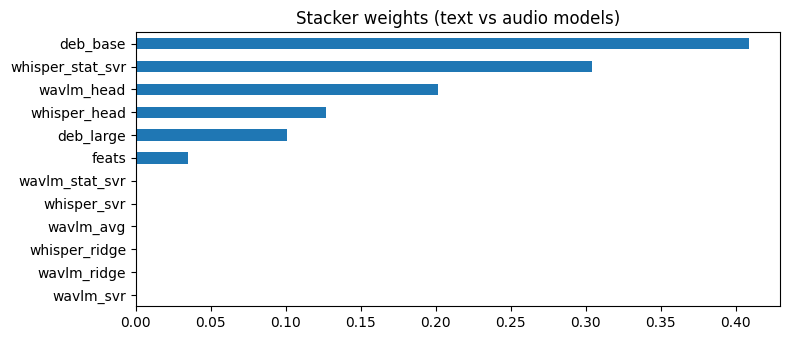

In [46]:
names = ['deb_base', 'deb_large', 'wavlm_ridge', 'wavlm_svr', 'wavlm_avg', 'feats', 'whisper_ridge', 'whisper_svr',
         'whisper_head', 'wavlm_head', 'whisper_stat_svr', 'wavlm_stat_svr']
P_oof = np.column_stack([oof_deb, oof_large, oof_aud, oof_aud_svr, oof_aud_avg, oof_b5, oof_wh, oof_wh_svr,
                         oof_head_wh, oof_head_wl, oof_stat_wh, oof_stat_wl])
P_te  = np.column_stack([test_deb, test_large, test_aud, test_aud_svr, test_aud_avg, test_b5, test_wh, test_wh_svr,
                         test_head_wh, test_head_wl, test_stat_wh, test_stat_wl])
print('correlation of OOF predictions\n', pd.DataFrame(np.corrcoef(P_oof.T), index=names, columns=names).round(2).to_string())

def nested_stack(P, splitter):
    so = np.zeros(len(y2))
    for tr_idx, va_idx in splitter.split(P, strata5):
        so[va_idx] = LinearRegression(positive=True).fit(P[tr_idx], y2[tr_idx], sample_weight=w5[tr_idx]).predict(P[va_idx])
    return so
stack_oof = nested_stack(P_oof, skf2)
stacker = LinearRegression(positive=True).fit(P_oof, y2, sample_weight=w5)
final_oof, final_test = bias_correct(stack_oof, stacker.predict(P_te))

# a single stacker split is noisy (+-0.005), so the comparison is repeated over 5 different stacker splits
cv5 = lambda P: [wrmse(y2, bias_correct(nested_stack(P, StratifiedKFold(5, shuffle=True, random_state=100 + r)), np.zeros(len(test_df)))[0], w5)
                 for r in range(5)]
s_old, s_new = cv5(P_oof[:, :8]), cv5(P_oof)
print('\nnested CV over 5 stacker splits | clip-mean audio only (v10): %.4f | + frame-level audio (v17, final): %.4f | better on %d of 5 splits'
      % (np.mean(s_old), np.mean(s_new), sum(b < a for a, b in zip(s_old, s_new))))

wts = pd.Series(stacker.coef_, index=names)
print('\nstacker weights:', wts.round(3).to_dict(), '| sum %.2f | intercept %.3f' % (wts.sum(), stacker.intercept_))
plt.figure(figsize=(8, 3.5)); wts.sort_values().plot.barh(); plt.title('Stacker weights (text vs audio models)'); plt.tight_layout(); plt.show()

The weights sum to more than 1 with a negative intercept: every single model regresses towards the mean
(under-predicts strong speakers, over-predicts weak ones), and the stacker learns to undo part of that shrinkage.

## 9. Evaluation & visualisations

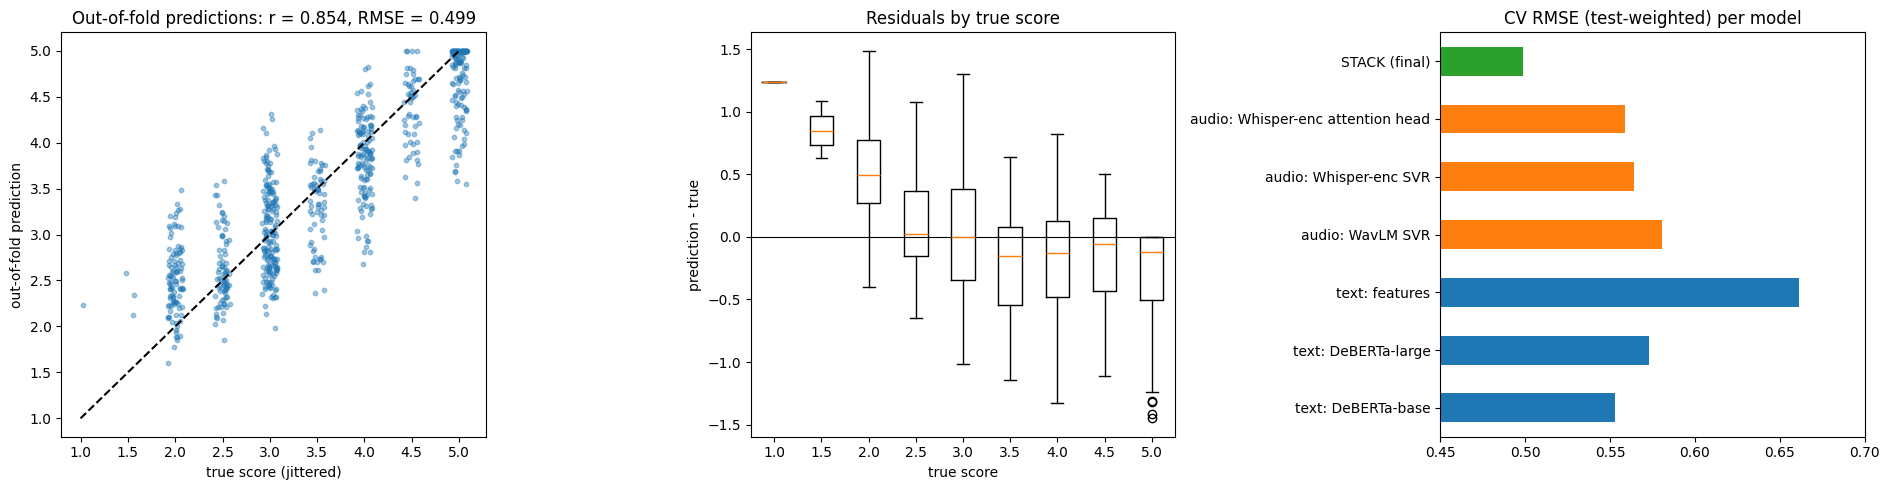

Error by true score (test-weighted)
         n  mean_pred   bias  share_of_error
y                                           
1.0    1.0      2.236  1.236           0.024
1.5    3.0      2.354  0.854           0.005
2.0  102.0      2.460  0.460           0.281
2.5   79.0      2.566  0.066           0.063
3.0  174.0      3.004  0.004           0.191
3.5   64.0      3.391 -0.109           0.052
4.0  124.0      3.783 -0.217           0.203
4.5   52.0      4.284 -0.216           0.049
5.0  133.0      4.618 -0.382           0.132


In [47]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
r_cv = wpearson(y2, final_oof, w5)
ax[0].scatter(y2 + np.random.uniform(-0.08, 0.08, len(y2)), final_oof, s=10, alpha=0.4)
ax[0].plot([1, 5], [1, 5], 'k--'); ax[0].set_xlabel('true score (jittered)'); ax[0].set_ylabel('out-of-fold prediction')
ax[0].set_title(f'Out-of-fold predictions: r = {r_cv:.3f}, RMSE = {wrmse(y2, final_oof, w5):.3f}')
lv = sorted(np.unique(y2)); res = final_oof - y2
ax[1].boxplot([res[y2 == s] for s in lv]); ax[1].set_xticklabels(lv); ax[1].axhline(0, c='k', lw=0.8)
ax[1].set_xlabel('true score'); ax[1].set_ylabel('prediction - true'); ax[1].set_title('Residuals by true score')
comp = {'text: DeBERTa-base': oof_deb, 'text: DeBERTa-large': oof_large, 'text: features': oof_b5,
        'audio: WavLM SVR': oof_aud_svr, 'audio: Whisper-enc SVR': oof_wh_svr, 'audio: Whisper-enc attention head': oof_head_wh}
vals = {k: wrmse(y2, bias_correct(v, np.zeros(len(test_df)))[0], w5) for k, v in comp.items()}
vals['STACK (final)'] = wrmse(y2, final_oof, w5)
pd.Series(vals).plot.barh(ax=ax[2], color=['tab:blue'] * 3 + ['tab:orange'] * 3 + ['tab:green'])
ax[2].set_xlim(0.45, 0.70); ax[2].set_title('CV RMSE (test-weighted) per model'); plt.tight_layout(); plt.show()

err = pd.DataFrame({'y': y2, 'pred': final_oof, 'w': w5}); err['e'] = err.pred - err.y; tot = (err.w * err.e ** 2).sum()
print('Error by true score (test-weighted)')
print(err.groupby('y').apply(lambda g: pd.Series({'n': len(g), 'mean_pred': np.average(g.pred, weights=g.w),
      'bias': np.average(g.e, weights=g.w), 'share_of_error': (g.w * g.e ** 2).sum() / tot})).round(3).to_string())

### 9b. Why the score plateaued (1): prompts in the test set that training never saw
Clustering the transcripts by topic shows that the test set contains prompts that are absent or rare in training
(e.g. *floods*: 0 training / 22 test clips; *role model / TV show*: 6 / 46). Re-running cross-validation with whole topics
held out (= unseen prompts) shows which models depend on having seen the prompt.

In [48]:
from sklearn.model_selection import GroupKFold
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
topic = np.load(need('topic_labels.npy')) if (not RUN_FULL and find('topic_labels.npy')) else \
        KMeans(n_clusters=12, n_init=10, random_state=SEED).fit(EMB).labels_
tt, te_t = topic[idx_tr], topic[idx_te]
tv = TfidfVectorizer(stop_words='english', min_df=3, max_features=5000).fit(all_df.text)
Wm, vocab = tv.transform(all_df.text), np.array(tv.get_feature_names_out())
print(pd.DataFrame([{'topic': c, 'top words': ' '.join(vocab[np.asarray(Wm[topic == c].mean(0)).ravel().argsort()[::-1][:4]]),
                     'train clips': int((tt == c).sum()), 'test clips': int((te_t == c).sum())} for c in range(12)]).to_string(index=False))

gkf = list(GroupKFold(n_splits=5).split(np.zeros(len(y2)), y2, groups=tt))
def cv_split(make, X):
    o = np.zeros(len(y2))
    for a, b in gkf: o[b] = fit_w(make(), X[a], y2[a], w5[a]).predict(X[b])
    return o
if RUN_FULL or find('topic_oof_deb_base.npy') is None:
    topic_deb = train_deberta('microsoft/deberta-v3-base', epochs=5, lr=2e-5, bs=16, splits=gkf)[0]
else:
    topic_deb = np.load(need('topic_oof_deb_base.npy'))
shift = {'text: DeBERTa-base': (oof_deb, topic_deb),
         'text: features': (oof_b5, np.mean([cv_split(mk, Xa) for mk, Xa, _ in feat_models.values()], axis=0)),
         'audio: WavLM SVR': (oof_aud_svr, cv_split(make_svr, X3_tr)),
         'audio: Whisper-enc SVR': (oof_wh_svr, cv_split(make_svr, XW_tr))}
print('\nCV RMSE (test-weighted): random folds vs folds that hold out whole topics (= unseen prompts)')
for k, (o_r, o_t) in shift.items():
    r1, r2 = wrmse(y2, bias_correct(o_r, np.zeros(len(test_df)))[0], w5), wrmse(y2, bias_correct(o_t, np.zeros(len(test_df)))[0], w5)
    print(f'{k:<24s} random folds {r1:.3f} | unseen topics {r2:.3f} | change {r2 - r1:+.3f}')

 topic                       top words  train clips  test clips
     0           flood water uh floods            0          22
     1               uh know really um           26          18
     2        market people uh crowded          117          11
     3                day life best uh           94          19
     4        resort beach pool really           43           6
     5               goal life um want           62           6
     6     uh instagram favorite movie            6          46
     7               place uh visit um           83          26
     8 playground school children kids          138          14
     9      goal uh challenges achieve           41           8
    10        airport uh people flight           27          22
    11               hobby enjoy uh um           95          18

CV RMSE (test-weighted): random folds vs folds that hold out whole topics (= unseen prompts)
text: DeBERTa-base       random folds 0.553 | unseen topics 0.588 | change

Text models lose accuracy on unseen prompts (they partly learn topic shortcuts), the speech models do not. Because only about a
third of the test clips are on unseen prompts and the stack already mixes text and audio, the whole effect is worth only
~0.004 RMSE on the full test set — so re-weighting the stack for these clips (v16) and pseudo-labelling were not pursued further.
It does explain why giving the topic-robust **speech** models more weight (§7c) helped the leaderboard more than CV predicted.

### 9c. Why the score plateaued (2): transcript quality

In [49]:
def max_repeat_4gram(t):
    tk = re.findall(r"[a-z']+", t.lower()); g = [' '.join(tk[i:i + 4]) for i in range(len(tk) - 3)]
    return int(pd.Series(g).value_counts().max()) if g else 0
def longest_gap(wj):
    w = json.loads(wj); return max([b[1] - a[2] for a, b in zip(w[:-1], w[1:])], default=0)
loops = np.array([max_repeat_4gram(t) for t in all_df.text]); gaps = np.array([longest_gap(w) for w in all_df.words])
nwords = np.array([len(t.split()) for t in all_df.text])
sq = w5 * (final_oof - y2) ** 2
flags = {'Whisper repetition loop (4-gram x4+)': loops >= 4, 'silence gap > 5 s': gaps > 5, 'fewer than 50 words': nwords < 50}
print(f'{"flag":<38s} {"train":>6s} {"test":>5s} | test-weighted RMSE flagged vs rest | share of error')
for k, f in flags.items():
    ft = f[idx_tr]
    print(f'{k:<38s} {int(ft.sum()):6d} {int(f[idx_te].sum()):5d} | {wrmse(y2[ft], final_oof[ft], w5[ft]):.3f} vs {wrmse(y2[~ft], final_oof[~ft], w5[~ft]):.3f}'
          f'          | {sq[ft].sum() / sq.sum():.0%} of error from {w5[ft].sum() / w5.sum():.0%} of clips (test-weighted)')
print('\nexample of a broken test transcript:', all_df.text[idx_te[np.argmax(loops[idx_te])]][:160])

flag                                    train  test | test-weighted RMSE flagged vs rest | share of error
Whisper repetition loop (4-gram x4+)       24     8 | 0.552 vs 0.497          | 3% of error from 3% of clips (test-weighted)
silence gap > 5 s                          59     6 | 0.522 vs 0.498          | 4% of error from 4% of clips (test-weighted)
fewer than 50 words                        14     3 | 0.761 vs 0.487          | 8% of error from 3% of clips (test-weighted)

example of a broken test transcript: So, uh, what is crowded market? Crowded markets already after customers. A lot of options. They're usually full of well-established business with years of exper


Whisper occasionally loops or skips silence, and the flagged clips are somewhat harder, but they explain only a small share of the
error. A manual check of the worst-predicted clips (speech energy compared with Whisper's word timestamps) found that Whisper did
**not** drop speech: the largest errors are clips whose text and audio look like typical 3–3.5 answers but were rated 5
(or rated 2 despite clean, fluent sentences). This points to rater inconsistency as the main limit on the achievable RMSE.

## 10. Final results (incl. the required training-data RMSE)

In [50]:
# Training-data RMSE: the stacker fitted on all 732 training clips, scored on those same clips
# (its inputs are the base models' out-of-fold predictions, so this is close to - but slightly below - the CV value).
train_fit, _ = bias_correct(stacker.predict(P_oof), stacker.predict(P_te))
# In-sample RMSE of the refittable components (fitted and scored on all training clips)
insample = {'feature models': np.mean([fit_w(mk(), Xa, y2, w5).predict(Xa) for mk, Xa, _ in feat_models.values()], axis=0),
            'WavLM SVR': fit_w(make_svr(), X3_tr, y2, w5).predict(X3_tr),
            'Whisper-enc SVR': fit_w(make_svr(), XW_tr, y2, w5).predict(XW_tr)}
if ST is not None:
    insample['Whisper mean+std SVR'] = fit_w(make_svr(), ST[idx_tr][:, :2560], y2, w5).predict(ST[idx_tr][:, :2560])

print('=' * 78)
print('FINAL RESULTS  (732 rubric-scored training clips)')
print('-' * 78)
print(f'TRAINING DATA RMSE (final ensemble, unweighted)      : {rmse(y2, train_fit):.4f} | Pearson {pearsonr(y2, train_fit)[0]:.4f}')
print(f'TRAINING DATA RMSE (final ensemble, test-weighted)   : {wrmse(y2, train_fit, w5):.4f}')
print(f'5-fold CV RMSE     (out-of-fold, unweighted)         : {rmse(y2, final_oof):.4f} | Pearson {pearsonr(y2, final_oof)[0]:.4f}')
print(f'5-fold CV RMSE     (out-of-fold, test-weighted)      : {wrmse(y2, final_oof, w5):.4f} | Pearson {wpearson(y2, final_oof, w5):.4f}'
      f' | MAE {wmae(y2, final_oof, w5):.4f}')
for k, v in insample.items():
    print(f'  in-sample training RMSE, {k:<16s}: {rmse(y2, v):.4f}')
print('Kaggle public leaderboard (this submission, v17)      : 0.3417')
print('=' * 78)

FINAL RESULTS  (732 rubric-scored training clips)
------------------------------------------------------------------------------
TRAINING DATA RMSE (final ensemble, unweighted)      : 0.4956 | Pearson 0.8724
TRAINING DATA RMSE (final ensemble, test-weighted)   : 0.4906
5-fold CV RMSE     (out-of-fold, unweighted)         : 0.4977 | Pearson 0.8713
5-fold CV RMSE     (out-of-fold, test-weighted)      : 0.4988 | Pearson 0.8539 | MAE 0.3886
  in-sample training RMSE, feature models  : 0.3899
  in-sample training RMSE, WavLM SVR       : 0.1621
  in-sample training RMSE, Whisper-enc SVR : 0.1803
  in-sample training RMSE, Whisper mean+std SVR: 0.1593
Kaggle public leaderboard (this submission, v17)      : 0.3417


## 11. Submission file

In [51]:
sub = pd.DataFrame({SUB_ID_COL: test_df[TEST_FILE_COL], SUB_TARGET_COL: final_test})
sub.to_csv(f'{WORK_DIR}/submission.csv', index=False)
print(sub.shape, '| prediction mean %.3f, std %.3f, min %.2f, max %.2f' % (final_test.mean(), final_test.std(), final_test.min(), final_test.max()))
ref = find('submission_v17.csv')
if ref is not None:
    r = pd.read_csv(ref)[SUB_TARGET_COL].values
    print('agreement with the submitted v17 file: corr %.4f | max abs diff %.4f' % (np.corrcoef(r, final_test)[0, 1], np.abs(r - final_test).max()))
sub.head()

(216, 2) | prediction mean 3.249, std 0.849, min 1.91, max 5.00
agreement with the submitted v17 file: corr 1.0000 | max abs diff 0.0000


,filename,label
0,audio_128.wav,2.867134
1,audio_156.wav,3.898932
2,audio_19.wav,4.550644
3,audio_108.wav,2.059895
4,audio_206.wav,2.009593


## 12. Report

### Approach
Grammar is judged from *what* is said, but human raters *listen* to the speech. The final system therefore combines
**text models** (Whisper transcript → fine-tuned DeBERTa-v3 and grammar/fluency features) with **speech models**
(frozen WavLM-large and Whisper-large-v3 encoder representations → Ridge/SVR on clip means, and attention-pooling heads
on the 80 ms frame sequences), combined by a non-negative linear stacker.

### Preprocessing
* Audio: 16 kHz mono. ASR with Whisper `turbo`, a disfluent initial prompt (keeps fillers and errors), word timestamps.
* Removed the 37 artificial score-0 clips (§3). Kept the 732 rubric-scored clips.
* Length shift handled with importance weights (short ×2.84, long ×0.41) and a per-length bias correction (§4).
* Speech models: chunked inference (20 s / 30 s windows) over real (non-padding) frames; clip-level mean (+ std) pooling,
  and frame sequences averaged to 80 ms for the attention heads.

### Evaluation
One fixed 5-fold split stratified by score × length, shared by all models; metrics are reported on out-of-fold predictions
and weighted to the test length mix. The stacker is evaluated with a second, independent split (nested); because one
stacker split moves the score by ±0.005, versions were compared over 5 different stacker splits.

### Experiment log

| Ver. | Change | CV RMSE (test-weighted, nested) | Public LB |
|---|---|---|---|
| v1 | Whisper → hand-crafted features + mpnet → Ridge/SVR/LightGBM | 0.679 | 0.5180 |
| v2 | drop score-0 batch + length-dependent features | — | 0.5304 (worse: exposed the length shift) |
| v5 | + length-aware weights & bias correction | 0.661 | 0.5230 |
| v6 | + fine-tuned DeBERTa-v3-base | 0.558 | 0.4173 |
| v7 | + DeBERTa-v3-large | 0.544 | 0.3758 |
| v8 | + frozen WavLM-large speech model | 0.515 | 0.3524 |
| v9 | learned (stacked) blend weights | 0.509 | 0.3517 |
| v10 | + frozen Whisper-large-v3 encoder | 0.502 (0.506 over 5 stacker splits) | 0.3510 |
| v11 | 3-seed DeBERTa average + joint audio SVR | 0.506 | 0.3533 |
| v12 | + DeBERTa on transcripts with `(pause)` markers | 0.495 | 0.3546 |
| v13 | + Qwen2.5-7B-Instruct "LLM examiner" with the rubric | 0.496 | 0.3534 |
| v14 | family-level stack (text / audio / features / LLM) | — | 0.3547 |
| v15 | + WavLM-large fine-tuned end-to-end (8 s crops, top 12 layers, 5 epochs) | 0.501 (no gain) | not submitted |
| v16 | topic-robust stack weights for test clips on unseen prompts | — | 0.3544 |
| **v17** | **+ attention heads on 80 ms frames and mean+std SVRs (Whisper encoder, WavLM) — final** | **0.501 (5 splits)** | **0.3417** |
| v18 | + w2v-BERT 2.0 (clip-mean SVR + frame heads) | 0.495 (5 splits) | 0.3433 (no gain, v17 kept) |

### Findings
1. **Speech matters as much as text.** Frozen WavLM / Whisper-encoder features + SVR (CV ≈ 0.56–0.58) are as good as a
   fine-tuned DeBERTa on transcripts (0.56), and their errors are only moderately correlated (≈ 0.7), so combining them helps most.
2. **Deeper layers carry the signal** (layer-probing plot, §7): acoustic early layers are weak, upper layers are best.
3. **Seed variance is large with 732 clips**: identical DeBERTa settings gave CV RMSE 0.562 / 0.576 / 0.591 with three seeds.
   A stack that leaned on the luckiest run (v12) looked better in CV but worse on the leaderboard → v10 was kept.
4. **A 7B LLM reading the transcript with the official rubric correlates only 0.41 zero-shot** and predicts "3" for most clips.
   The information raters use to separate weak speakers is largely not in the (ASR-cleaned) transcript.
5. **Error is concentrated in score-2 speakers** (≈ 28 % of the squared error; predicted ≈ 2.47 on average).
   Prediction spread (0.82) vs label spread (0.96) matches what an RMSE-optimal model with r ≈ 0.86 should do,
   so stretching predictions would not help — only better discrimination would.
6. **End-to-end fine-tuning of WavLM-large did not beat frozen features** with 732 clips (CV RMSE 0.641 vs 0.558;
   correlation with the frozen-feature model 0.92) and added nothing to the stack. No model family separated
   score-2.0 from score-2.5 speakers, which suggests rater noise at the low end limits what any model can reach.
7. **Keeping the time dimension of the speech gave the last real gain.** Attention heads on 80 ms frames beat clip-mean SVRs
   (Whisper encoder 0.559 vs 0.564) and moved the leaderboard from 0.3510 to 0.3417 — more than the CV gain (0.506 → 0.501)
   predicted, consistent with the speech models being robust to the prompt shift (finding 8).
8. **The test set contains unseen prompts** (§9b). With whole topics held out, DeBERTa loses 0.035 RMSE and the text features
   0.058, while the speech models do not degrade at all.
9. **A third speech encoder (w2v-BERT 2.0) improved CV on every stacker split but not the leaderboard** (0.3433 vs 0.3417).
   With 216 test clips, leaderboard differences of a few thousandths are within noise, so the simpler v17 was kept.
10. **Broken transcripts are real but minor** (§9c), and the worst errors are clips rated far from what both the text and the
   audio suggest — the remaining error is dominated by rater inconsistency rather than by a missing model component.
11. **The predictions carry no global bias on the test set.** Two diagnostic submissions with all v17 predictions shifted by
   +0.1 / −0.1 both scored worse (0.3507 / 0.3442 vs 0.3417); the best shift implied by the three scores is about −0.02,
   worth < 0.001. The length-based bias correction (§4) is therefore well calibrated, and the final submission is unshifted v17.

### Limitations & next steps
* Label noise: averaging more raters per clip would help more than any model change at this point.
* Re-transcribe the ~30 clips where Whisper looped, e.g. with a second decoding pass or a more literal CTC model.
* Fine-tune a speech encoder on full-length clips (the 8 s crops used for the WavLM fine-tune lose sentence structure).
* Refit the final models on 100 % of the training data instead of averaging the 5 fold models.